In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight/Brown_Blight_1.jpg
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight/Brown_Blight_10.jpg
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight/Brown_Blight_100.jpg
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight/Brown_Blight_101.jpg
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight/Brown_Blight_102.jpg
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight/Brown_Blight_103.jpg
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight/Brown_Blight_104.jpg
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight/Brown_Blight_105.jpg
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight/Brown_Blight_106.jpg
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight/Brown_Blight_107.jpg
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight/Brown_Blight_108.jpg
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight/Brown_Blight_109.jpg
/kaggle/input/datasets/sadiaaniqua/tea-leaf

In [2]:
!find /kaggle/input -maxdepth 4 -type d

/kaggle/input
/kaggle/input/datasets
/kaggle/input/datasets/sadiaaniqua
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Blight
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Healthy_Leaf
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Helopeltis
/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease/Red_Rust


In [3]:
import os, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from PIL import Image
import torch, torch.nn as nn, torch.nn.functional as F
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import train_test_split
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay, classification_report

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

SEED = 42
torch.manual_seed(SEED); np.random.seed(SEED)

Using device: cuda


In [4]:
root = "/kaggle/input/datasets/sadiaaniqua/tea-leaf-disease"   # <-- change if your path differs

EXT = (".jpg", ".jpeg", ".png")
classes = sorted(d for d in os.listdir(root) if os.path.isdir(os.path.join(root, d)))
paths, labels, total_bytes = [], [], 0

for i, c in enumerate(classes):
    files = [f for f in os.listdir(os.path.join(root, c)) if f.lower().endswith(EXT)]
    for f in files:
        p = os.path.join(root, c, f)
        paths.append(p); labels.append(i); total_bytes += os.path.getsize(p)
    print(f"{c:15s}: {len(files)} images")

paths, labels = np.array(paths), np.array(labels)
print("\nClasses     :", classes)
print("Total images:", len(paths))
print(f"Total size  : {total_bytes / 1024**3:.2f} GB")

Blight         : 555 images
Healthy_Leaf   : 650 images
Helopeltis     : 675 images
Red_Rust       : 620 images

Classes     : ['Blight', 'Healthy_Leaf', 'Helopeltis', 'Red_Rust']
Total images: 2500
Total size  : 3.39 GB


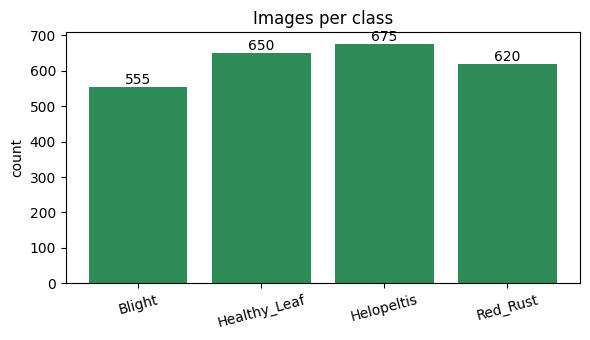

In [5]:
# Class distribution
counts = np.bincount(labels)
plt.figure(figsize=(6, 3.5))
plt.bar(classes, counts, color="seagreen")
for i, v in enumerate(counts): plt.text(i, v, str(v), ha="center", va="bottom")
plt.title("Images per class"); plt.ylabel("count"); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

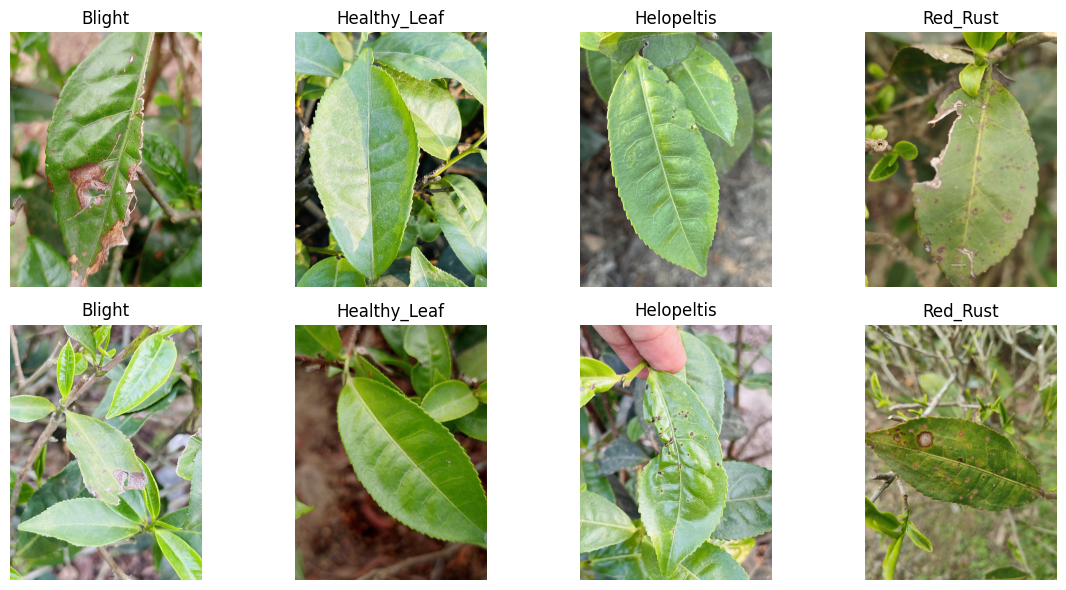

In [6]:
# Look at the data: 2 sample images per class
fig, axes = plt.subplots(2, len(classes), figsize=(3 * len(classes), 6))
for i, c in enumerate(classes):
    idx = np.where(labels == i)[0][:2]
    for r, k in enumerate(idx):
        axes[r, i].imshow(Image.open(paths[k]).convert("RGB"))
        axes[r, i].set_title(c); axes[r, i].axis("off")
plt.tight_layout(); plt.show()

In [7]:
p_tr, p_tmp, y_tr, y_tmp = train_test_split(paths, labels, test_size=0.30, stratify=labels, random_state=SEED)
p_va, p_te, y_va, y_te   = train_test_split(p_tmp, y_tmp, test_size=0.50, stratify=y_tmp, random_state=SEED)

print("Train:", len(p_tr), "| Val:", len(p_va), "| Test:", len(p_te))

Train: 1750 | Val: 375 | Test: 375


In [8]:
IMG_SIZE, BATCH_SIZE = 128, 32

basic_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
])

class LeafDataset(Dataset):
    def __init__(self, paths, labels, transform):
        self.paths, self.labels, self.transform = paths, labels, transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        img = Image.open(self.paths[i]).convert("RGB")
        return self.transform(img), int(self.labels[i])

train_ds = LeafDataset(p_tr, y_tr, basic_transform)
val_ds   = LeafDataset(p_va, y_va, basic_transform)
test_ds  = LeafDataset(p_te, y_te, basic_transform)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True,  num_workers=2)
val_loader   = DataLoader(val_ds,   batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE, shuffle=False, num_workers=2)
print("Classes:", classes)

Classes: ['Blight', 'Healthy_Leaf', 'Helopeltis', 'Red_Rust']


In [9]:
class SimpleCNN(nn.Module):
    def __init__(self, num_classes=4, p_dropout=0.0):
        super().__init__()
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.pool  = nn.MaxPool2d(2, 2)
        self.dropout = nn.Dropout(p_dropout)
        self.fc1 = nn.Linear(64 * 16 * 16, 128)
        self.fc2 = nn.Linear(128, num_classes)

    def forward(self, x):
        x = self.pool(F.relu(self.conv1(x)))   # 128 -> 64
        x = self.pool(F.relu(self.conv2(x)))   # 64  -> 32
        x = self.pool(F.relu(self.conv3(x)))   # 32  -> 16
        x = torch.flatten(x, 1)
        x = self.dropout(x)
        x = F.relu(self.fc1(x))
        return self.fc2(x)

model = SimpleCNN(num_classes=len(classes), p_dropout=0.0).to(device)
print(model)
print(f"\nTotal trainable parameters: {sum(p.numel() for p in model.parameters()):,}")

SimpleCNN(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (dropout): Dropout(p=0.0, inplace=False)
  (fc1): Linear(in_features=16384, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=4, bias=True)
)

Total trainable parameters: 2,121,380


In [10]:
def train_model(model, train_loader, val_loader, epochs=20, lr=1e-3):
    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    history = {"train_loss": [], "val_loss": [], "train_acc": [], "val_acc": []}

    for epoch in range(epochs):
        # ---- training ----
        model.train()
        run_loss, correct, total = 0.0, 0, 0
        for imgs, lbls in train_loader:
            imgs, lbls = imgs.to(device), lbls.to(device)
            optimizer.zero_grad()
            out = model(imgs)
            loss = criterion(out, lbls)
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * imgs.size(0)
            correct  += (out.argmax(1) == lbls).sum().item()
            total    += lbls.size(0)
        tr_loss, tr_acc = run_loss / total, correct / total

        # ---- validation ----
        model.eval()
        run_loss, correct, total = 0.0, 0, 0
        with torch.no_grad():
            for imgs, lbls in val_loader:
                imgs, lbls = imgs.to(device), lbls.to(device)
                out = model(imgs)
                run_loss += criterion(out, lbls).item() * imgs.size(0)
                correct  += (out.argmax(1) == lbls).sum().item()
                total    += lbls.size(0)
        va_loss, va_acc = run_loss / total, correct / total

        for k, v in zip(history, (tr_loss, va_loss, tr_acc, va_acc)):
            history[k].append(v)
        print(f"Epoch {epoch+1:02d}/{epochs} | train loss {tr_loss:.4f} acc {tr_acc:.4f} | val loss {va_loss:.4f} acc {va_acc:.4f}")
    return history

EPOCHS = 20
history_plain = train_model(model, train_loader, val_loader, epochs=EPOCHS)

Epoch 01/20 | train loss 1.1601 acc 0.4777 | val loss 0.8914 acc 0.6320
Epoch 02/20 | train loss 0.8272 acc 0.6526 | val loss 0.8008 acc 0.6880
Epoch 03/20 | train loss 0.6991 acc 0.7206 | val loss 0.7796 acc 0.6800
Epoch 04/20 | train loss 0.5508 acc 0.7851 | val loss 0.5928 acc 0.7547
Epoch 05/20 | train loss 0.4044 acc 0.8411 | val loss 0.6099 acc 0.7840
Epoch 06/20 | train loss 0.3031 acc 0.8971 | val loss 0.7017 acc 0.7600
Epoch 07/20 | train loss 0.2712 acc 0.9023 | val loss 0.5341 acc 0.8293
Epoch 08/20 | train loss 0.1625 acc 0.9457 | val loss 0.5747 acc 0.8213
Epoch 09/20 | train loss 0.1161 acc 0.9611 | val loss 0.6967 acc 0.8107
Epoch 10/20 | train loss 0.1011 acc 0.9651 | val loss 0.5361 acc 0.8533
Epoch 11/20 | train loss 0.0529 acc 0.9857 | val loss 0.6628 acc 0.8240
Epoch 12/20 | train loss 0.0473 acc 0.9863 | val loss 0.6905 acc 0.8507
Epoch 13/20 | train loss 0.0241 acc 0.9960 | val loss 0.7790 acc 0.8533
Epoch 14/20 | train loss 0.0082 acc 0.9989 | val loss 0.7950 acc

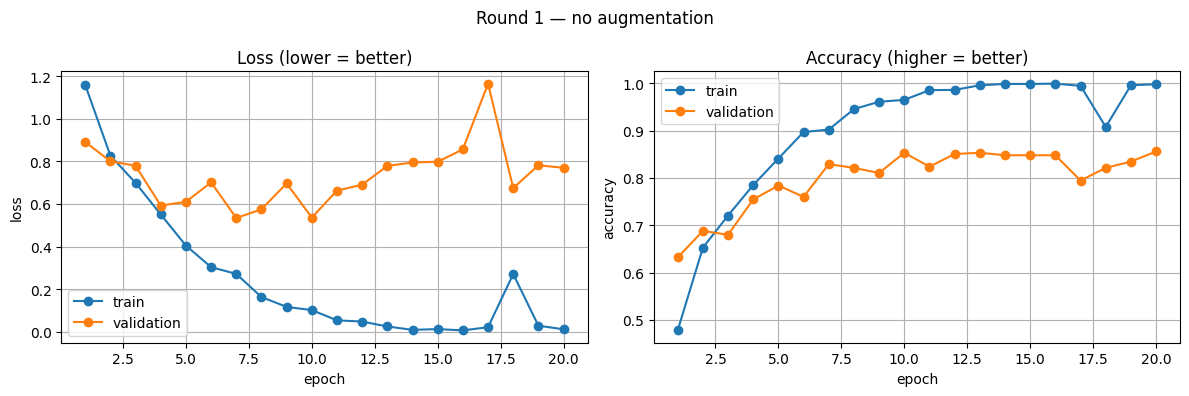

In [11]:
def plot_history(history, title=""):
    ep = range(1, len(history["train_loss"]) + 1)
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
    ax1.plot(ep, history["train_loss"], "o-", label="train")
    ax1.plot(ep, history["val_loss"],   "o-", label="validation")
    ax1.set_title("Loss (lower = better)"); ax1.set_xlabel("epoch"); ax1.set_ylabel("loss"); ax1.legend(); ax1.grid(True)
    ax2.plot(ep, history["train_acc"], "o-", label="train")
    ax2.plot(ep, history["val_acc"],   "o-", label="validation")
    ax2.set_title("Accuracy (higher = better)"); ax2.set_xlabel("epoch"); ax2.set_ylabel("accuracy"); ax2.legend(); ax2.grid(True)
    fig.suptitle(title); plt.tight_layout(); plt.show()

plot_history(history_plain, "Round 1 — no augmentation")

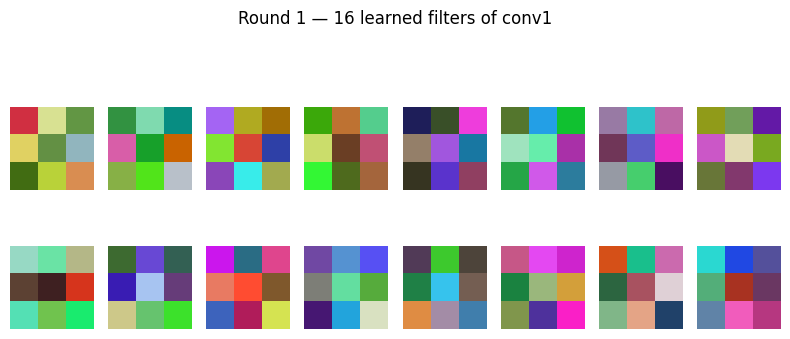

In [12]:
w = model.conv1.weight.data.clone().cpu()
w = (w - w.min()) / (w.max() - w.min() + 1e-8)
plt.figure(figsize=(8, 4))
for i in range(16):
    plt.subplot(2, 8, i + 1); plt.imshow(w[i].permute(1, 2, 0)); plt.axis("off")
plt.suptitle("Round 1 — 16 learned filters of conv1"); plt.tight_layout(); plt.show()

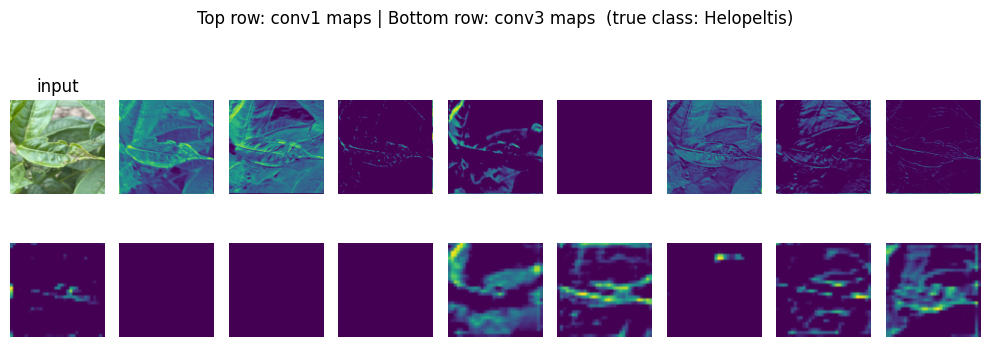

In [13]:
# (2) Feature maps of conv1 and conv3 for one validation image
img, lbl = val_ds[0]
x = img.unsqueeze(0).to(device)
model.eval()
with torch.no_grad():
    fm1 = F.relu(model.conv1(x)).cpu()[0]                          # 16 x 128 x 128
    h = model.pool(F.relu(model.conv1(x)))
    h = model.pool(F.relu(model.conv2(h)))
    fm3 = F.relu(model.conv3(h)).cpu()[0]                          # 64 x 32 x 32

plt.figure(figsize=(10, 4))
plt.subplot(2, 9, 1); plt.imshow(img.permute(1, 2, 0)); plt.title("input"); plt.axis("off")
for i in range(8):
    plt.subplot(2, 9, i + 2); plt.imshow(fm1[i], cmap="viridis"); plt.axis("off")
for i in range(9):
    plt.subplot(2, 9, i + 10); plt.imshow(fm3[i], cmap="viridis"); plt.axis("off")
plt.suptitle(f"Top row: conv1 maps | Bottom row: conv3 maps  (true class: {classes[lbl]})")
plt.tight_layout(); plt.show()

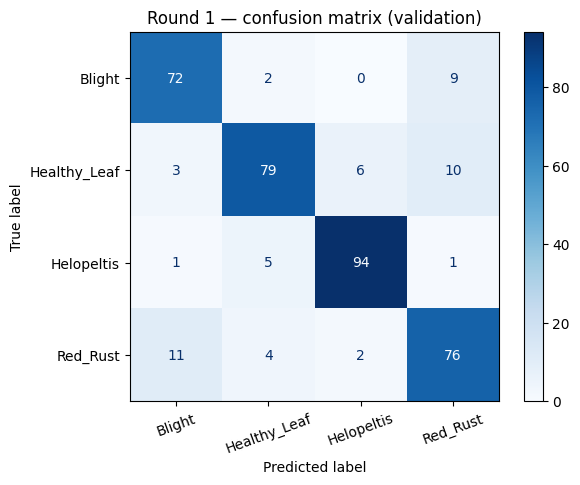

              precision    recall  f1-score   support

      Blight       0.83      0.87      0.85        83
Healthy_Leaf       0.88      0.81      0.84        98
  Helopeltis       0.92      0.93      0.93       101
    Red_Rust       0.79      0.82      0.80        93

    accuracy                           0.86       375
   macro avg       0.85      0.86      0.85       375
weighted avg       0.86      0.86      0.86       375



In [14]:
def get_predictions(model, loader):
    model.eval()
    preds, targets = [], []
    with torch.no_grad():
        for imgs, lbls in loader:
            preds.append(model(imgs.to(device)).argmax(1).cpu())
            targets.append(lbls)
    return torch.cat(preds).numpy(), torch.cat(targets).numpy()

y_pred, y_true = get_predictions(model, val_loader)
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=classes).plot(cmap="Blues", values_format="d")
plt.title("Round 1 — confusion matrix (validation)"); plt.xticks(rotation=20); plt.show()
print(classification_report(y_true, y_pred, target_names=classes))

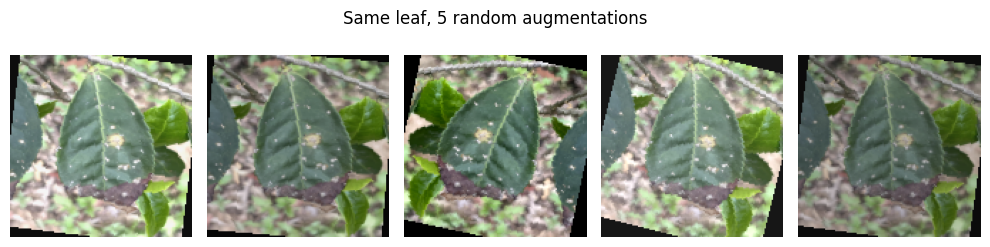

In [15]:
train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
])

train_ds_aug = LeafDataset(p_tr, y_tr, train_transform)
train_loader_aug = DataLoader(train_ds_aug, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)

# same image, 5 random augmentations
plt.figure(figsize=(10, 2.5))
for i in range(5):
    plt.subplot(1, 5, i + 1); plt.imshow(train_ds_aug[0][0].permute(1, 2, 0)); plt.axis("off")
plt.suptitle("Same leaf, 5 random augmentations"); plt.tight_layout(); plt.show()

Epoch 01/20 | train loss 1.2117 acc 0.4354 | val loss 0.9958 acc 0.5920
Epoch 02/20 | train loss 0.9720 acc 0.5760 | val loss 0.9052 acc 0.6667
Epoch 03/20 | train loss 0.8766 acc 0.6417 | val loss 0.8242 acc 0.7040
Epoch 04/20 | train loss 0.8223 acc 0.6549 | val loss 0.7031 acc 0.6933
Epoch 05/20 | train loss 0.7571 acc 0.6806 | val loss 0.7153 acc 0.7173
Epoch 06/20 | train loss 0.7197 acc 0.7200 | val loss 0.6202 acc 0.7600
Epoch 07/20 | train loss 0.6661 acc 0.7486 | val loss 0.6452 acc 0.7680
Epoch 08/20 | train loss 0.6712 acc 0.7377 | val loss 0.6464 acc 0.7440
Epoch 09/20 | train loss 0.6696 acc 0.7423 | val loss 0.6814 acc 0.7520
Epoch 10/20 | train loss 0.6027 acc 0.7709 | val loss 0.6039 acc 0.7627
Epoch 11/20 | train loss 0.5792 acc 0.7777 | val loss 0.6214 acc 0.7627
Epoch 12/20 | train loss 0.5511 acc 0.7897 | val loss 0.5596 acc 0.7947
Epoch 13/20 | train loss 0.5495 acc 0.7840 | val loss 0.5332 acc 0.7760
Epoch 14/20 | train loss 0.4734 acc 0.8263 | val loss 0.5357 acc

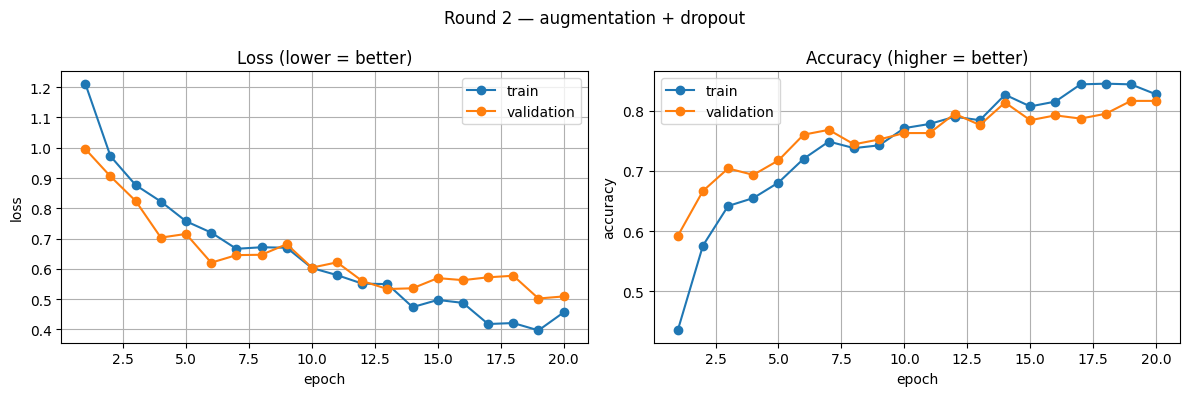

In [16]:
torch.manual_seed(SEED)
model_aug = SimpleCNN(num_classes=len(classes), p_dropout=0.5).to(device)
history_aug = train_model(model_aug, train_loader_aug, val_loader, epochs=EPOCHS)
plot_history(history_aug, "Round 2 — augmentation + dropout")

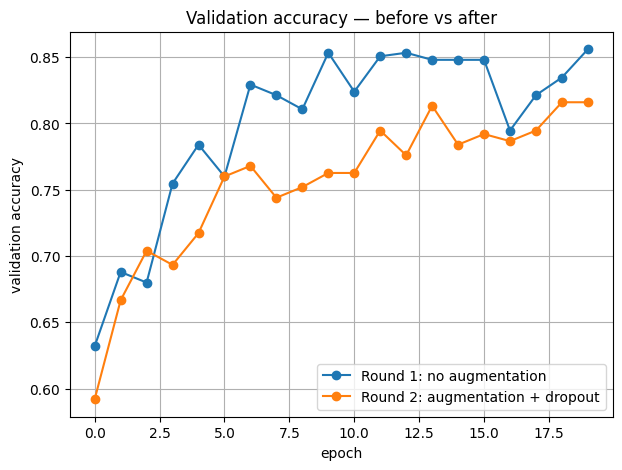

Best val acc (Round 1): 0.856
Best val acc (Round 2): 0.816
Final train-val gap (Round 1): 0.142
Final train-val gap (Round 2): 0.011


In [17]:
plt.figure(figsize=(7, 5))
plt.plot(history_plain["val_acc"], "o-", label="Round 1: no augmentation")
plt.plot(history_aug["val_acc"],   "o-", label="Round 2: augmentation + dropout")
plt.title("Validation accuracy — before vs after"); plt.xlabel("epoch"); plt.ylabel("validation accuracy")
plt.legend(); plt.grid(True); plt.show()

print(f"Best val acc (Round 1): {max(history_plain['val_acc']):.3f}")
print(f"Best val acc (Round 2): {max(history_aug['val_acc']):.3f}")
print(f"Final train-val gap (Round 1): {history_plain['train_acc'][-1] - history_plain['val_acc'][-1]:.3f}")
print(f"Final train-val gap (Round 2): {history_aug['train_acc'][-1] - history_aug['val_acc'][-1]:.3f}")

Test accuracy: 0.7920



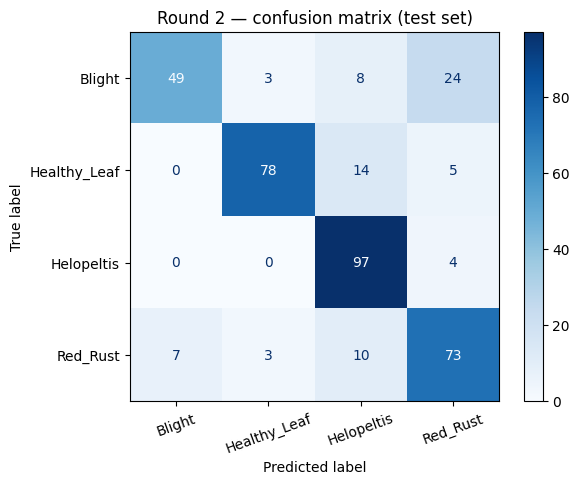

              precision    recall  f1-score   support

      Blight       0.88      0.58      0.70        84
Healthy_Leaf       0.93      0.80      0.86        97
  Helopeltis       0.75      0.96      0.84       101
    Red_Rust       0.69      0.78      0.73        93

    accuracy                           0.79       375
   macro avg       0.81      0.78      0.78       375
weighted avg       0.81      0.79      0.79       375



In [18]:
y_pred, y_true = get_predictions(model_aug, test_loader)
print(f"Test accuracy: {(y_pred == y_true).mean():.4f}\n")

ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred), display_labels=classes).plot(cmap="Blues", values_format="d")
plt.title("Round 2 — confusion matrix (test set)"); plt.xticks(rotation=20); plt.show()
print(classification_report(y_true, y_pred, target_names=classes))

Misclassified: 78 of 375


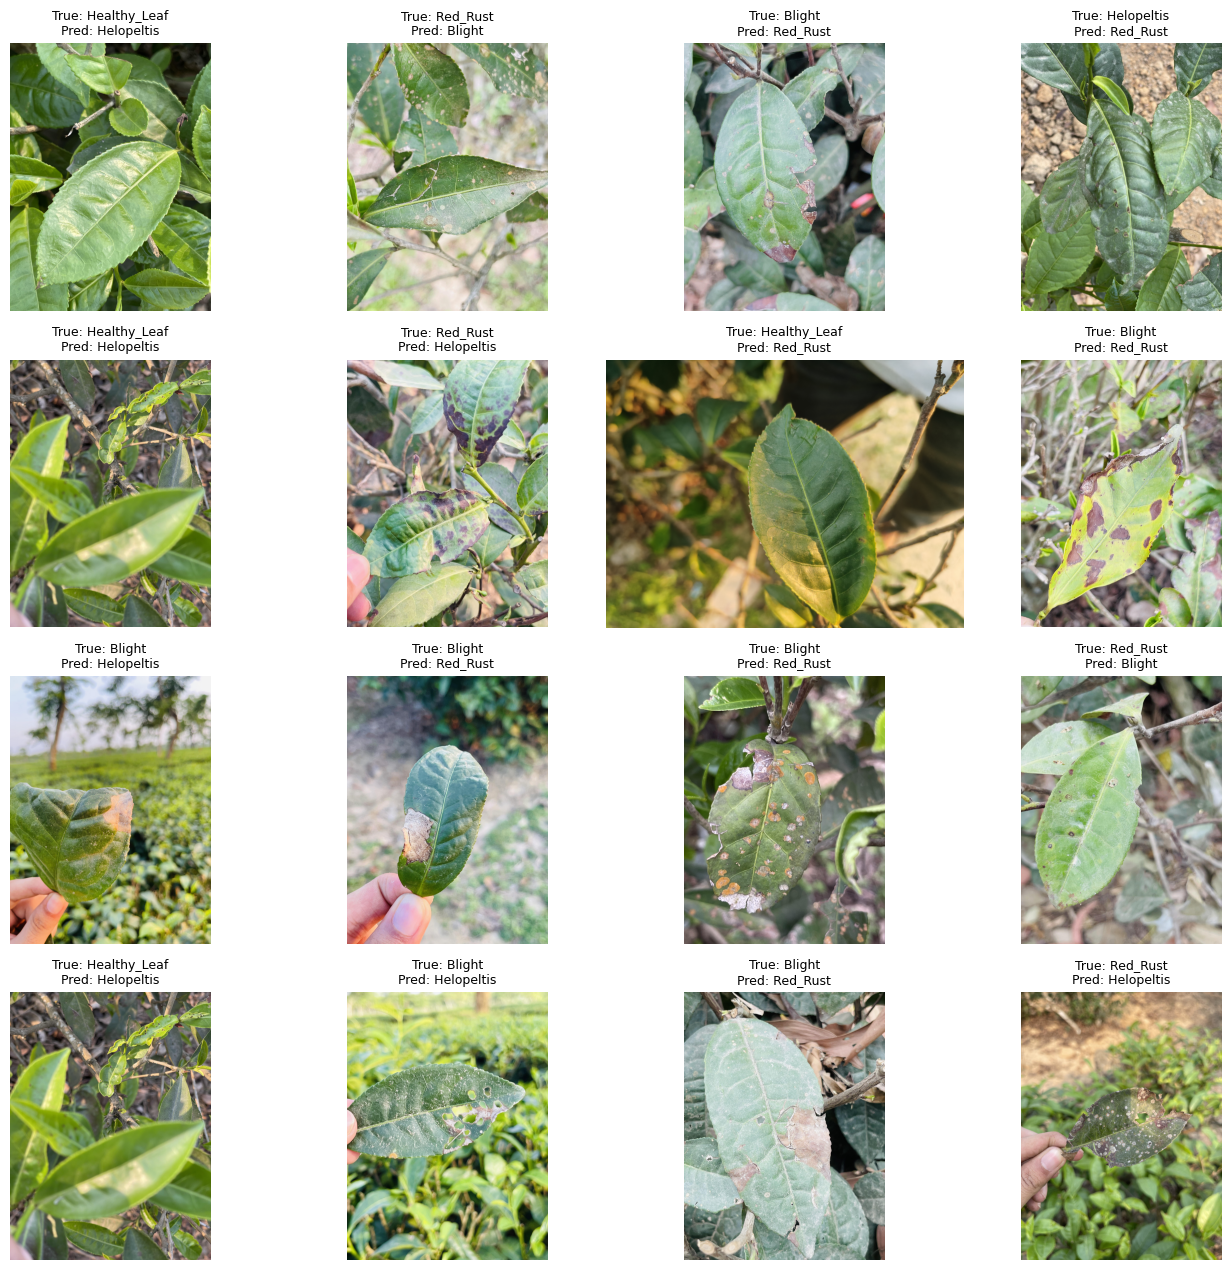

In [19]:
wrong = np.where(y_true != y_pred)[0]
print("Misclassified:", len(wrong), "of", len(y_true))

n = min(16, len(wrong))
if n > 0:
    plt.figure(figsize=(14, 3.2 * ((n + 3) // 4)))
    for j, k in enumerate(wrong[:n]):
        plt.subplot((n + 3) // 4, 4, j + 1)
        plt.imshow(Image.open(test_ds.paths[k]).convert("RGB"))
        plt.title(f"True: {classes[y_true[k]]}\nPred: {classes[y_pred[k]]}", fontsize=9)
        plt.axis("off")
    plt.tight_layout(); plt.show()

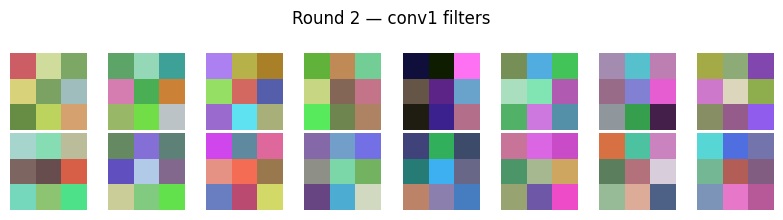

In [20]:
# Filters + last-layer feature maps of the Round 2 model
w = model_aug.conv1.weight.data.clone().cpu()
w = (w - w.min()) / (w.max() - w.min() + 1e-8)
plt.figure(figsize=(8, 2.2))
for i in range(16):
    plt.subplot(2, 8, i + 1); plt.imshow(w[i].permute(1, 2, 0)); plt.axis("off")
plt.suptitle("Round 2 — conv1 filters"); plt.tight_layout(); plt.show()